# Lesson 14 - Balancing by removing data: the same number of ships in every class

Lesson 13 kept every clip and balanced the classes with **weights**: every class and every ship counted the same
in training. Here we try the other way: **remove data** until every class has the same number of ships and the
same number of clips, and train with no weights at all.

Everything else is the same as in lesson 13: the six classes, the five folds, the **test sets (never cut)**, both
feature sets and both models. Only the training data change, so the two ways of balancing are compared on exactly
the same test clips.

| Section | Question |
|---|---|
| 1. How the data are cut | how many ships and clips are left |
| 2. Results | removal against weights |
| 3. Which classes change | per-class accuracy and confusions |
| 4. What it means | |

```
python src/six_classes_equal.py      # -> runs/six_classes_equal/ (about 7 minutes, CPU; needs lesson 13's features)
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import six_classes as S
import six_classes_equal as E
from paths import RUNS_DIR

OUT = RUNS_DIR / "six_classes_equal"
summary = json.loads((OUT / "results.json").read_text())
removal = pd.DataFrame(summary["results"]).assign(balancing="removal")
weights = pd.DataFrame(json.loads((S.OUT_DIR / "results.json").read_text())["results"]).assign(balancing="weights")
table = pd.read_parquet(ROOT / "data" / "clips.parquet")
pd.set_option("display.width", 160)

## 1. How the data are cut

In every run (one test fold, the next fold for validation, three for training), the training set, the
validation set and training + validation together are each cut the same way:

1. **Equal ships:** every class keeps as many ships as the class with the fewest ships has (tanker), chosen at
   random. Background keeps the same number of recording days.
2. **Equal clips:** every class keeps as many clips as the class with the fewest clips among the kept ships. That
   is cargo: its ships have only 1-2 clips each. The clips are taken evenly: first one clip from every kept ship,
   then a second one from some of them.

Here is fold 1's training + validation set (the data the final model is trained on), before and after:

              before       after removal      
               ships clips         ships clips
label                                         
background       642  2882           186   267
cargo           2017  2881           186   267
fishing          191  2889           186   267
pleasurecraft    324  2874           186   267
tanker           186  2875           186   267
tug              237  2874           186   267

kept: 1,602 of 17,275 clips (9%)


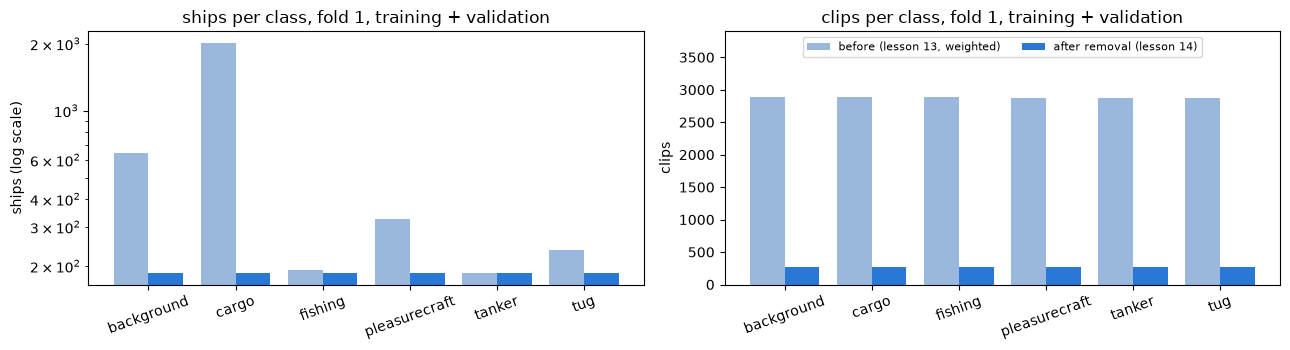

In [2]:
folds = S.make_folds(table)
full = S.Fold(table, folds, 1)
cut = E.EqualFold(full, seed=100)          # fold 1, draw 0 of the run
before = pd.DataFrame({"label": np.array(S.CLASSES6)[full.y["train+validation"]],
                       "ship": full.ships["train+validation"]}).groupby("label").agg(
    ships=("ship", "nunique"), clips=("ship", "size"))
after = cut.counts("train+validation")
both = pd.concat({"before": before, "after removal": after}, axis=1)
print(both)
print(f"\nkept: {after.clips.sum():,} of {before.clips.sum():,} clips ({after.clips.sum() / before.clips.sum():.0%})")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
x = np.arange(len(S.CLASSES6))
for j, col in enumerate(["ships", "clips"]):
    ax[j].bar(x - 0.2, before[col], 0.4, label="before (lesson 13, weighted)", color="#9ab8de")
    ax[j].bar(x + 0.2, after[col], 0.4, label="after removal (lesson 14)", color="#2a78d6")
    ax[j].set_xticks(x, S.CLASSES6, rotation=20); ax[j].set_title(f"{col} per class, fold 1, training + validation")
ax[0].set_yscale("log"); ax[0].set_ylabel("ships (log scale)"); ax[1].set_ylabel("clips")
ax[1].set_ylim(0, 3900); ax[1].legend(fontsize=8, loc="upper center", ncol=2); plt.tight_layout(); plt.show()

Over all five folds and all random draws:

In [3]:
counts = pd.read_csv(OUT / "counts.csv")
tv = counts[counts.split == "train+validation"].groupby(["fold", "draw"]).agg(
    ships_per_class=("ships", "first"), clips_per_class=("clips", "first"), clips=("clips", "sum"))
print(tv.groupby("fold").mean().round(0))
used = removal.groupby(["fold", "draw"]).n_train_clips.first().mean()
print(f"\naverage training clips: {used:,.0f} with removal, against about 17,280 with weights")

      ships_per_class  clips_per_class   clips
fold                                          
1               186.0            265.0  1590.0
2               187.0            267.0  1604.0
3               186.0            261.0  1564.0
4               186.0            265.0  1590.0
5               187.0            267.0  1604.0

average training clips: 1,590 with removal, against about 17,280 with weights


Which ships are removed is random, so every run is repeated with **5 different random draws**. The spread between
draws shows how much the result depends on which ships happen to be kept.

## 2. Results: removal against weights

Test folds, as in lesson 13 (balanced accuracy, chance 16.7 %). For removal, each fold's number is first averaged
over the 5 draws; ± is the spread between the 5 folds. "Spread between draws" is the standard deviation over the
5 draws of the 5-fold average.

                                               balanced_accuracy    macro_f1 per_ship_balanced_accuracy spread between draws
features         model               balancing                                                                              
engineered       gradient boosting   removal          57.0 ± 1.0  56.6 ± 1.0                 66.2 ± 0.9                  0.4
                 logistic regression removal          56.9 ± 1.3  56.5 ± 1.4                 64.7 ± 1.6                  0.2
simple (no MFCC) gradient boosting   removal          53.5 ± 0.8  53.1 ± 0.8                 62.1 ± 1.4                  0.6
                 logistic regression removal          52.7 ± 0.8  52.2 ± 0.8                 60.5 ± 1.0                  0.2
engineered       gradient boosting   weights          61.9 ± 1.1  61.4 ± 1.2                 70.5 ± 2.2                     
                 logistic regression weights          60.8 ± 1.3  60.4 ± 1.4                 67.3 ± 1.8                     


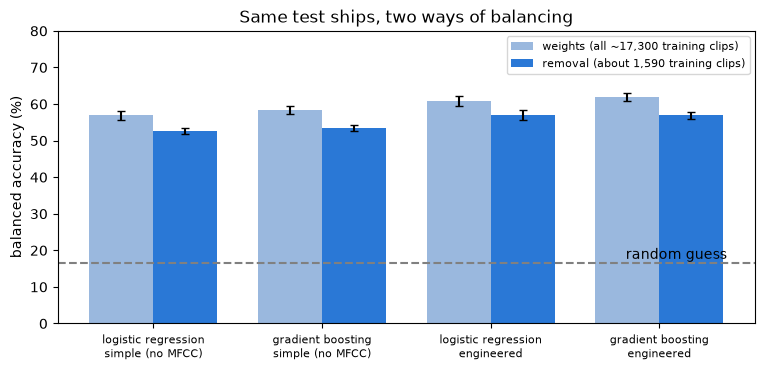

In [4]:
cols = ["balanced_accuracy", "macro_f1", "per_ship_balanced_accuracy"]
per_fold = pd.concat([removal.groupby(["balancing", "features", "model", "fold"])[cols].mean(),
                      weights.groupby(["balancing", "features", "model", "fold"])[cols].mean()])
g = per_fold.groupby(["features", "model", "balancing"], sort=False)
show = (100 * g.mean()).round(1).astype(str) + " ± " + (100 * g.std()).round(1).astype(str)
draw_spread = 100 * removal.groupby(["features", "model", "draw"]).balanced_accuracy.mean().groupby(
    ["features", "model"]).std()
show["spread between draws"] = [f"{draw_spread[f, m]:.1f}" if b == "removal" else "" for f, m, b in show.index]
print(show.to_string())

fig, ax = plt.subplots(figsize=(9, 3.8))
combos = [(f, m) for f in ("simple (no MFCC)", "engineered") for m in S.MODELS]
x = np.arange(len(combos))
for j, (b, color) in enumerate([("weights", "#9ab8de"), ("removal", "#2a78d6")]):
    means = [100 * g.mean().loc[(f, m, b), "balanced_accuracy"] for f, m in combos]
    errs = [100 * g.std().loc[(f, m, b), "balanced_accuracy"] for f, m in combos]
    ax.bar(x + (j - 0.5) * 0.38, means, 0.38, yerr=errs, capsize=3, color=color,
           label=f"{b} ({'all ~17,300' if b == 'weights' else f'about {used:,.0f}'} training clips)")
ax.axhline(100 / 6, color="grey", ls="--"); ax.text(3.4, 100 / 6 + 1, "random guess", ha="right")
ax.set_xticks(x, [f"{m}\n{f}" for f, m in combos], fontsize=8); ax.set_ylabel("balanced accuracy (%)")
ax.set_ylim(0, 80); ax.legend(fontsize=8); ax.set_title("Same test ships, two ways of balancing"); plt.show()

## 3. Which classes change

Recall per class (share of each class's test clips classified correctly), mean over folds (and draws):

               weights  removal  change
background        85.3     80.6    -4.7
cargo             64.7     51.4   -13.3
fishing           43.3     40.5    -2.8
pleasurecraft     64.1     58.2    -5.9
tanker            52.3     55.2     2.9
tug               61.7     56.1    -5.6

all combinations:
                          weights                                                                     removal                                        \
                 simple (no MFCC)                            engineered                      simple (no MFCC)                            engineered   
              logistic regression gradient boosting logistic regression gradient boosting logistic regression gradient boosting logistic regression   
background                   82.2              85.1                83.7              85.3                77.2              79.7                80.0   
cargo                        57.0              59.3                59.3              64.7        

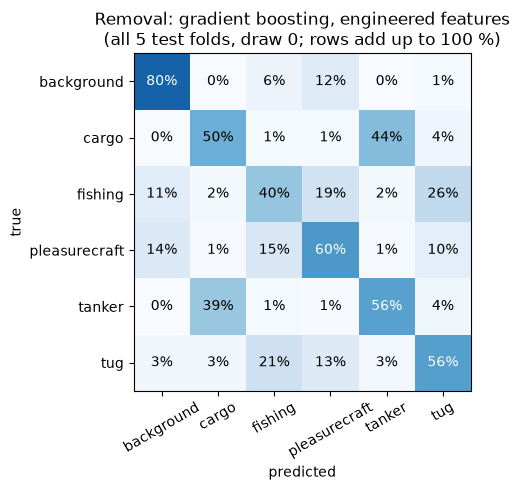

In [5]:
def recall_table(df):
    return pd.DataFrame({k: pd.DataFrame(list(v.per_class_recall)).mean()
                         for k, v in df.groupby(["features", "model"], sort=False)})


rec = pd.concat({"weights": recall_table(weights), "removal": recall_table(removal)}, axis=1)
best = ("engineered", "gradient boosting")
print((100 * rec.xs(best, axis=1, level=[1, 2])).round(1).assign(
    change=lambda d: (d.removal - d.weights).round(1)))
print("\nall combinations:"); print((100 * rec).round(1))

preds = pd.read_parquet(OUT / "predictions.parquet")
p = preds[(preds.features == best[0]) & (preds.model == best[1])]
cm = confusion_matrix(p.y, p[[f"p_{c}" for c in S.CLASSES6]].to_numpy().argmax(1), normalize="true")
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
ax.set_xticks(range(6), S.CLASSES6, rotation=30); ax.set_yticks(range(6), S.CLASSES6)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Removal: gradient boosting, engineered features\n(all 5 test folds, draw 0; rows add up to 100 %)")
plt.tight_layout(); plt.show()

Is there a pattern in which classes lose? Below, for gradient boosting with the engineered features: the share of
each class's ships that removal threw away (fold 1, training + validation), next to the change in its recall.

In [6]:
lost = pd.DataFrame({"ships removed": (1 - after.ships / before.ships).map("{:.0%}".format),
                     "clips removed": (1 - after.clips / before.clips).map("{:.0%}".format),
                     "recall change (points)": (100 * (rec[("removal", *best)] - rec[("weights", *best)])).round(1)})
print(lost.sort_values("recall change (points)"))

              ships removed clips removed  recall change (points)
cargo                   91%           91%                   -13.4
pleasurecraft           43%           91%                    -5.9
tug                     22%           91%                    -5.6
background              71%           91%                    -4.6
fishing                  3%           91%                    -2.8
tanker                   0%           91%                     2.9


**Roughly, the classes that lost the most ships lost the most accuracy.** Cargo kept only 186 of its 2,017 ships
and drops 13 points; pleasure craft, tug and background, which lost 22-71 % of their ships, drop 4.6-5.9 points
(background, the easiest class, less than its loss of ships would suggest); fishing and tanker kept (almost) all
their ships and change little. Tanker even gains 3 points, because the model no longer
sees ten times more different cargo ships than tankers and calls fewer tankers "cargo". Every class lost about
90 % of its clips, so the clips alone don't explain the order; **the number of different ships does**, as in
lesson 07 and the dataset's paper.

## 4. What it means

| Balanced accuracy, same test ships | Weights (lesson 13, ~17,300 training clips) | Removal (lesson 14, ~1,590 training clips) |
|---|---|---|
| simple + logistic regression | 56.9 ± 1.3 % | 52.7 ± 0.8 % |
| simple + gradient boosting | 58.4 ± 1.1 % | 53.5 ± 0.8 % |
| engineered + logistic regression | 60.8 ± 1.3 % | 56.9 ± 1.3 % |
| **engineered + gradient boosting** | **61.9 ± 1.1 %** | **57.0 ± 1.0 %** |

- **Removing data to equalise the classes costs 4-5 points**, for every model and feature set, on every one of
  the five folds. Per ship: 66.2 % against 70.5 % (engineered + gradient boosting).
- **It doesn't matter much which ships are removed:** the five random draws differ by only 0.2-0.6 points. The
  loss comes from how much is removed, not from bad luck.
- **What is lost is ship diversity.** Equal ships means every class is cut to the smallest class's 186 ships, so
  the big classes lose most of their different ships (cargo 91 %), and equal clips then keeps only 1-2 clips per
  ship. Cargo, which lost the most ships, lost the most accuracy (13 points).
- **The engineered features still win by about 4 points**, so that conclusion of lesson 13 holds either way.
- **Weights are the better way to balance here:** they make every class and every ship count the same, as removal
  does, but keep all the different ships. Removal would only be preferable if the extra data were harmful (for
  example many near-identical clips of a few ships), which is not the case in this dataset.

**A middle way, not tried here:** train several models, each on a different random equal-ships subset, and
average their predictions. Together they see far more of the ships, while each model is still trained on
balanced data.